# Foundations of Data Science
## Tutorial 4 — SVD, Power Method, and Applications

**Prepared by Dr. João A. Gonçalves**

This is the worked solution notebook for Tutorial 4. It mirrors the student notebook but includes complete code, numerical checks, and short interpretations.

The session focuses on the Singular Value Decomposition (SVD), numerical approximation with the power method, and three concrete use cases: quantum Hamiltonians, eBay-style recommendation systems, and computer vision.


### Suggested time budget

| Part | Topic | Suggested time |
|---:|---|---:|
| 1 | SVD and low-rank approximation | 20 min |
| 2 | Power method approximation | 20 min |
| 3 | Quantum Hamiltonian example | 15 min |
| 4 | eBay-style recommendation example | 15 min |
| 5 | Computer vision example | 15 min |
| 6 | Final checks and discussion | 5 min |

The intended outcome is practical: by the end, you should be able to say what the singular values measure, how to approximate the largest one without calling `np.linalg.svd`, and why low-rank structure is useful.


### Setup

Run this cell once. It fixes the random seed, imports the required packages, and defines a few helper routines.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
np.set_printoptions(precision=6, suppress=True)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def print_matrix(name, M):
	print(f"{name} =")
	print(np.array(M))
	print()


def sorted_svd(A):
	U, s, Vt = np.linalg.svd(A, full_matrices=False)
	return U, s, Vt


def reconstruct_from_svd(U, s, Vt, k=None):
	if k is None:
		k = len(s)
	return (U[:, :k] * s[:k]) @ Vt[:k, :]


def relative_frobenius_error(A, A_hat):
	return np.linalg.norm(A - A_hat, ord="fro") / np.linalg.norm(A, ord="fro")


def storage_ratio(m, n, k):
	full = m * n
	low_rank = k * (m + n + 1)
	return low_rank / full


def schmidt_entropy(s, eps=1e-15):
	p = s**2
	p = p / np.sum(p)
	p = p[p > eps]
	return -np.sum(p * np.log2(p))


def show_image(title, image):
	plt.figure(figsize=(4, 4))
	plt.imshow(image, cmap="gray", vmin=0, vmax=1)
	plt.title(title)
	plt.axis("off")
	plt.show()


## 1. SVD as rotated stretching

For any real matrix $A \in \mathbb{R}^{m \times n}$, the SVD writes

$$
A = U \Sigma V^T.
$$

The columns of $V$ are input directions, the columns of $U$ are output directions, and the singular values in $\Sigma$ are the stretching factors. Unlike the eigenvalue decomposition, the SVD works for rectangular matrices.

We start with

$$
A = \begin{pmatrix}
3 & 2 & 2 \\
2 & 3 & -2
\end{pmatrix}.
$$


### Exercise 1.1 — compute and verify an SVD


In [2]:
A = np.array([[3, 2, 2],
              [2, 3, -2]], dtype=float)

U, s, Vt = sorted_svd(A)
A_reconstructed = reconstruct_from_svd(U, s, Vt)

print("Singular values:")
print(s)
print()
print_matrix("U.T @ U", U.T @ U)
print_matrix("Vt @ Vt.T", Vt @ Vt.T)
print_matrix("A reconstructed", A_reconstructed)
print("Reconstruction check:", np.allclose(A, A_reconstructed))


Singular values:
[5. 3.]

U.T @ U =
[[1. 0.]
 [0. 1.]]

Vt @ Vt.T =
[[1. 0.]
 [0. 1.]]

A reconstructed =
[[ 3.  2.  2.]
 [ 2.  3. -2.]]

Reconstruction check: True


The singular values are $5$ and $3$ up to numerical precision. Since this matrix has shape $2\times 3$, the reduced SVD stores two left singular vectors, two singular values, and two right singular vectors. The reconstruction check confirms that no information is lost when all singular values are kept.


### Low-rank approximation

If the singular values are sorted in decreasing order, the rank-$k$ approximation is

$$
A_k = \sum_{i=1}^{k} \sigma_i u_i v_i^T.
$$

Keeping only the largest singular values gives the best rank-$k$ approximation in Frobenius norm. This is the core reason why SVD is useful for compression, denoising, dimensionality reduction, and latent-factor models.


### Exercise 1.2 — keep only the dominant singular directions


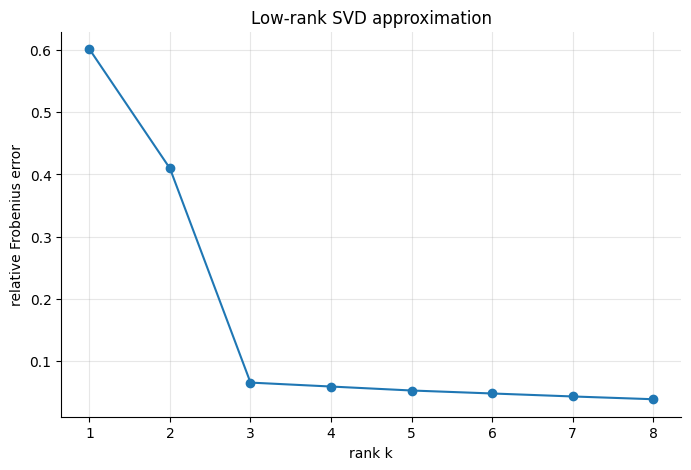

First 8 singular values:
[39.316165 21.647062 19.889061  1.384415  1.316503  1.081067  1.031175
  0.941129]

rank 1: relative error = 0.6011
rank 2: relative error = 0.4096
rank 3: relative error = 0.0657
rank 4: relative error = 0.0594
rank 5: relative error = 0.0530
rank 6: relative error = 0.0482
rank 7: relative error = 0.0434
rank 8: relative error = 0.0390


In [3]:
m, n, true_rank = 30, 20, 3
left = rng.normal(size=(m, true_rank))
right = rng.normal(size=(true_rank, n))
M = left @ right + 0.15 * rng.normal(size=(m, n))

U_M, s_M, Vt_M = sorted_svd(M)
errors = []

for k in range(1, 9):
	M_k = reconstruct_from_svd(U_M, s_M, Vt_M, k=k)
	errors.append(relative_frobenius_error(M, M_k))

plt.figure()
plt.plot(range(1, 9), errors, marker="o")
plt.xlabel("rank k")
plt.ylabel("relative Frobenius error")
plt.title("Low-rank SVD approximation")
plt.grid(alpha=0.3)
plt.show()

print("First 8 singular values:")
print(s_M[:8])
print()
for k, err in enumerate(errors, start=1):
	print(f"rank {k}: relative error = {err:.4f}")


The error drops most strongly while the approximation is recovering the dominant latent rank. After that, additional singular vectors mostly describe noise. In real data analysis this elbow is rarely perfectly clean, but the principle is the same.


## 2. Approximating SVD with the power method

Calling `np.linalg.svd` is usually the right thing to do in real work. Still, it is useful to understand how the dominant singular direction can be found iteratively.

For a matrix $A$, the right singular vectors are eigenvectors of

$$
A^T A v_i = \sigma_i^2 v_i.
$$

Therefore, the largest singular value can be approximated by applying the power method to $B=A^TA$.


### Exercise 2.1 — implement the power method


In [4]:
def power_method_symmetric(B, n_iter=100, tol=1e-10, seed=0):
	rng_local = np.random.default_rng(seed)
	v = rng_local.normal(size=B.shape[0])
	v = v / np.linalg.norm(v)

	for iteration in range(1, n_iter + 1):
		w = B @ v
		w_norm = np.linalg.norm(w)
		if w_norm == 0:
			raise ValueError("Power method encountered the zero vector.")
		v_next = w / w_norm

		if np.linalg.norm(v_next - v) < tol or np.linalg.norm(v_next + v) < tol:
			v = v_next
			break
		v = v_next

	eigenvalue = float(v @ B @ v)
	return eigenvalue, v, iteration

B_test = np.array([[4, 1],
                   [1, 3]], dtype=float)

lam, vec, n_steps = power_method_symmetric(B_test)
print("dominant eigenvalue:", lam)
print("dominant eigenvector:", vec)
print("iterations:", n_steps)
print("NumPy eigenvalues:", np.linalg.eigvalsh(B_test))


dominant eigenvalue: 4.618033988749895
dominant eigenvector: [0.850651 0.525731]
iterations: 38
NumPy eigenvalues: [2.381966 4.618034]


The Rayleigh quotient $v^TBv$ gives the eigenvalue estimate once the vector has converged. The sign of the eigenvector is arbitrary, so convergence must allow both $v_{new}\approx v$ and $v_{new}\approx -v$.


### Exercise 2.2 — from the power method to the leading singular triplet


In [5]:
B = M.T @ M
lambda_1, v_1, n_steps = power_method_symmetric(B, n_iter=500, tol=1e-12, seed=4)
sigma_1 = np.sqrt(max(lambda_1, 0.0))
u_1 = M @ v_1 / sigma_1

U_np, s_np, Vt_np = sorted_svd(M)

print("power-method sigma_1:", sigma_1)
print("NumPy sigma_1:", s_np[0])
print("absolute difference:", abs(sigma_1 - s_np[0]))
print("iterations:", n_steps)
print("left vector has norm:", np.linalg.norm(u_1))


power-method sigma_1: 39.316164788809864
NumPy sigma_1: 39.31616478880985
absolute difference: 1.4210854715202004e-14
iterations: 26
left vector has norm: 1.0


The dominant singular value is recovered accurately. This is the basic idea behind scalable truncated SVD methods: avoid computing the full decomposition when only the largest singular directions are needed.


### Optional extension — repeated power method with deflation

The simplest way to approximate more than one singular triplet is deflation: find the leading rank-1 component, subtract it, and repeat. This is pedagogically useful, though robust production implementations use more stable Krylov or randomized methods.


In [6]:
def truncated_svd_power(A, k, n_iter=500, tol=1e-12):
	R = A.copy()
	U_list = []
	s_list = []
	Vt_list = []

	for j in range(k):
		B = R.T @ R
		lambda_j, v_j, _ = power_method_symmetric(B, n_iter=n_iter, tol=tol, seed=10 + j)
		sigma_j = np.sqrt(max(lambda_j, 0.0))
		if sigma_j < 1e-14:
			break
		u_j = R @ v_j / sigma_j
		R = R - sigma_j * np.outer(u_j, v_j)

		U_list.append(u_j)
		s_list.append(sigma_j)
		Vt_list.append(v_j)

	return np.column_stack(U_list), np.array(s_list), np.vstack(Vt_list)

U_p, s_p, Vt_p = truncated_svd_power(M, k=3)
M_power3 = reconstruct_from_svd(U_p, s_p, Vt_p, k=3)
M_exact3 = reconstruct_from_svd(U_M, s_M, Vt_M, k=3)

print("power-method singular values:", s_p)
print("exact singular values:", s_M[:3])
print("power rank-3 error:", relative_frobenius_error(M, M_power3))
print("exact rank-3 error:", relative_frobenius_error(M, M_exact3))


power-method singular values: [39.316165 21.647062 19.889061]
exact singular values: [39.316165 21.647062 19.889061]
power rank-3 error: 0.06569757667121215
exact rank-3 error: 0.06569757667121215


The power-method approximation is close to the exact rank-3 SVD for this small example. The method is conceptually simple, but repeated deflation can accumulate numerical errors, especially when singular values are close together.


## 3. Use case: quantum Hamiltonians and Schmidt decomposition

A quantum Hamiltonian $H$ is Hermitian, so its energy levels are obtained from an eigenvalue decomposition, not primarily from an SVD. That distinction matters.

However, SVD is extremely useful once a quantum state has been obtained. For a two-subsystem state, reshape the state vector into a coefficient matrix $C$. The SVD

$$
C = U \Sigma V^\dagger
$$

gives the Schmidt decomposition. The squared singular values are probabilities. If only one singular value is non-zero, the state is separable. If several are important, the state is entangled.

We use a two-qubit transverse-field Ising Hamiltonian:

$$
H = - Z \otimes Z - h(X\otimes I + I\otimes X),
\qquad h=0.7.
$$


### Exercise 3.1 — ground state entanglement from an SVD


In [7]:
I2 = np.eye(2)
X = np.array([[0, 1],
              [1, 0]], dtype=float)
Z = np.array([[1, 0],
              [0, -1]], dtype=float)

h = 0.7
H = -np.kron(Z, Z) - h * (np.kron(X, I2) + np.kron(I2, X))

energies, states = np.linalg.eigh(H)
ground_energy = energies[0]
psi0 = states[:, 0]
C = psi0.reshape(2, 2)
Uq, sq, Vtq = sorted_svd(C)
entropy = schmidt_entropy(sq)

print("Hamiltonian:")
print(H)
print()
print("Ground-state energy:", ground_energy)
print("Schmidt coefficients:", sq)
print("Schmidt probabilities:", sq**2)
print("Schmidt entropy:", entropy)


Hamiltonian:
[[-1.  -0.7 -0.7 -0. ]
 [-0.7  1.  -0.  -0.7]
 [-0.7 -0.   1.  -0.7]
 [-0.  -0.7 -0.7 -1. ]]

Ground-state energy: -1.7204650534085255
Schmidt coefficients: [0.952296 0.305177]
Schmidt probabilities: [0.906867 0.093133]
Schmidt entropy: 0.4468426659060738


The SVD is being used on the reshaped ground-state vector, not as the primary solver for the Hamiltonian. The Schmidt entropy is non-zero, so the ground state is entangled across the two qubits. For larger quantum many-body systems, this same idea underlies tensor-network compression: keep only the largest Schmidt coefficients.


## 4. Use case: eBay-style recommendation systems

A marketplace recommendation problem can be represented as a sparse user-item matrix. Rows are users, columns are listings or item categories, and entries are ratings, clicks, purchases, or another interaction signal.

This is a toy eBay-style example, not a claim about eBay's production system. Real recommendation systems use much richer data, implicit feedback, ranking losses, constraints, and online evaluation. The point here is the linear algebra: low-rank SVD can discover latent preference factors.


### Exercise 4.1 — low-rank recommendations from a sparse matrix


In [8]:
users = ["User A", "User B", "User C", "User D", "User E", "User F"]
items = [
	"vintage camera",
	"noise-cancelling headphones",
	"gaming GPU",
	"running shoes",
	"coffee grinder",
	"mechanical keyboard",
	"linear algebra textbook",
]

R = np.array([
	[5, 4, np.nan, 1, 1, np.nan, 2],
	[4, 5, np.nan, 1, np.nan, 1, 2],
	[np.nan, 1, 5, 4, 1, 5, np.nan],
	[1, np.nan, 4, 5, 1, 4, 1],
	[1, 1, np.nan, 2, 5, np.nan, 4],
	[np.nan, 2, 4, np.nan, 4, 5, np.nan],
], dtype=float)

def fill_missing_with_user_means(R):
	R_filled = R.copy()
	global_mean = np.nanmean(R)

	for i in range(R.shape[0]):
		row_mean = np.nanmean(R[i])
		if np.isnan(row_mean):
			row_mean = global_mean
		missing = np.isnan(R[i])
		R_filled[i, missing] = row_mean

	return R_filled

R_filled = fill_missing_with_user_means(R)
U_r, s_r, Vt_r = sorted_svd(R_filled)
R_rank2 = reconstruct_from_svd(U_r, s_r, Vt_r, k=2)

target_user = users.index("User F")
unseen = np.isnan(R[target_user])
scores = R_rank2[target_user].copy()
scores[~unseen] = -np.inf
recommendation_index = int(np.argmax(scores))

print("Filled matrix:")
print(np.round(R_filled, 2))
print()
print("Predicted scores for User F:")
for item, score in zip(items, R_rank2[target_user]):
	marker = "(unseen)" if item == items[recommendation_index] else ""
	print(f"{item:30s} {score:7.3f} {marker}")
print()
print("Recommended item:", items[recommendation_index])


Filled matrix:
[[5.   4.   2.6  1.   1.   2.6  2.  ]
 [4.   5.   2.6  1.   2.6  1.   2.  ]
 [3.2  1.   5.   4.   1.   5.   3.2 ]
 [1.   2.67 4.   5.   1.   4.   1.  ]
 [1.   1.   2.6  2.   5.   2.6  4.  ]
 [3.75 2.   4.   3.75 4.   5.   3.75]]

Predicted scores for User F:
vintage camera                   3.379 
noise-cancelling headphones      2.619 
gaming GPU                       4.646 
running shoes                    4.086 (unseen)
coffee grinder                   3.072 
mechanical keyboard              4.796 
linear algebra textbook          3.487 

Recommended item: running shoes


The low-rank reconstruction smooths the sparse rating matrix through latent factors. In this toy matrix, the model identifies patterns such as electronics-oriented users, fitness/product users, and book/coffee-oriented users. This is the basic intuition behind matrix-factorization recommenders, although real recommender systems are not this naive.


## 5. Use case: computer vision and image compression

A grayscale image is a matrix. SVD therefore gives a direct compression method: keep only the largest singular values and discard the rest.

For an image with shape $m\times n$, storing the full image needs $mn$ numbers. A rank-$k$ SVD approximation stores

$$
k(m+n+1)
$$

numbers: $k$ left singular vectors, $k$ right singular vectors, and $k$ singular values.


### Exercise 5.1 — compress an image with truncated SVD


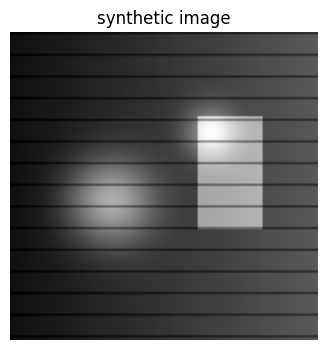

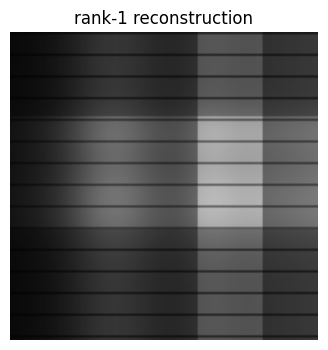

rank  1: relative error = 0.2569, storage ratio = 0.016


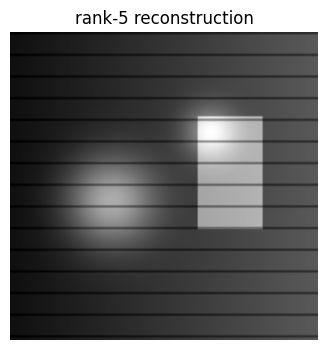

rank  5: relative error = 0.0000, storage ratio = 0.078


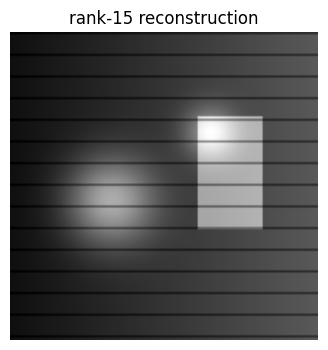

rank 15: relative error = 0.0000, storage ratio = 0.235


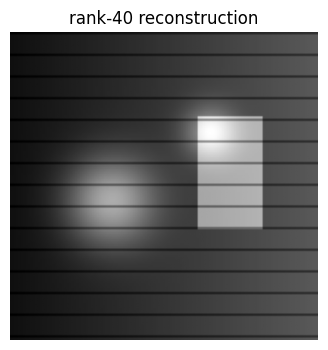

rank 40: relative error = 0.0000, storage ratio = 0.627


In [9]:
def make_synthetic_image(n=128):
	x = np.linspace(-1, 1, n)
	y = np.linspace(-1, 1, n)
	Xg, Yg = np.meshgrid(x, y)

	image = 0.15 + 0.25 * (Xg + 1) / 2
	image += 0.45 * np.exp(-((Xg + 0.35)**2 + (Yg - 0.10)**2) / 0.08)
	image += 0.30 * np.exp(-((Xg - 0.30)**2 + (Yg + 0.35)**2) / 0.03)
	image[35:82, 78:105] += 0.35
	image[::9, :] *= 0.65
	image = image - image.min()
	image = image / image.max()
	return image

image = make_synthetic_image()
show_image("synthetic image", image)

U_img, s_img, Vt_img = sorted_svd(image)

for k in [1, 5, 15, 40]:
	image_k = reconstruct_from_svd(U_img, s_img, Vt_img, k=k)
	image_k = np.clip(image_k, 0, 1)
	err = relative_frobenius_error(image, image_k)
	ratio = storage_ratio(*image.shape, k)
	show_image(f"rank-{k} reconstruction", image_k)
	print(f"rank {k:2d}: relative error = {err:.4f}, storage ratio = {ratio:.3f}")


The first few singular values capture the smooth global structure. Higher ranks recover sharper local details, such as the rectangle and stripe pattern. In computer vision, the same low-rank logic appears in PCA, denoising, background subtraction, latent representations, and compression.


## 6. Final checkpoint

1. Singular values measure how strongly the matrix stretches orthogonal input directions.
2. Rank-$k$ SVD works as compression because many real matrices have most of their energy concentrated in a small number of singular directions.
3. The power method is applied to $A^TA$ because its eigenvalues are $\sigma_i^2$ and its eigenvectors are the right singular vectors of $A$.
4. The Hamiltonian is Hermitian, so energies are obtained from an eigenvalue decomposition. SVD is then useful for analyzing the ground-state wavefunction through the Schmidt decomposition.
5. The recommender example captures latent-factor intuition, but real marketplace systems require sparse implicit feedback, ranking objectives, side information, freshness, fraud resistance, and online testing.
6. Smooth image structures often have low effective rank, so a few singular directions can recover most of the visible image.
